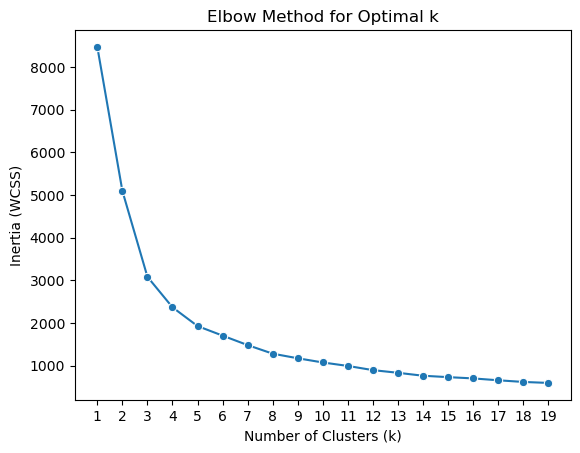

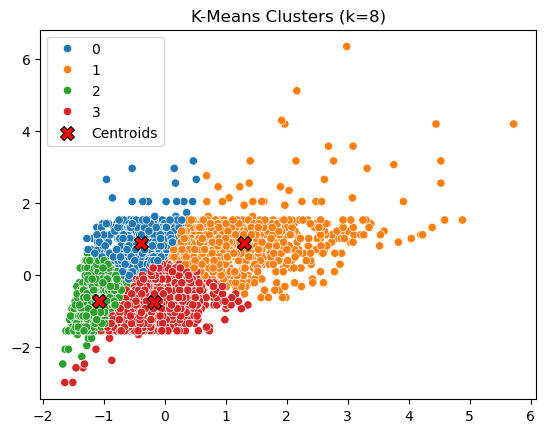

array([[2846.3260566 ,   43.74528302,   65.34079245],
       [5945.23803738,   43.84512684,   99.08925234],
       [1583.3161413 ,   28.00181159,   57.2348913 ],
       [3222.88532258,   27.80745968,   96.49792339]])

In [10]:
import pandas as pd

df = pd.read_csv('sales_data.csv', encoding='unicode_escape')
df.head()

df.isna().sum()

df.dtypes

df.nunique()

df = df[['SALES', 'QUANTITYORDERED', 'PRICEEACH']]

df.nunique()

from sklearn.preprocessing import StandardScaler

scalar = StandardScaler()
X_scaled = scalar.fit_transform(df)

from sklearn.cluster import KMeans

inertia = []
K = range(1, 20)

for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

import seaborn as sns
import matplotlib.pyplot as plt

sns.lineplot(y=inertia, x=K, marker='o')
plt.xticks(K)
plt.title("Elbow Method for Optimal k")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia (WCSS)")
plt.show()

optimal_k = 4

from sklearn.cluster import KMeans

model = KMeans(n_clusters=optimal_k, random_state=42)
model.fit(X_scaled)

df['class'] = model.predict(X_scaled)

df.head()

model.cluster_centers_

sns.scatterplot(x=X_scaled[:, 0], y=X_scaled[:, 1], hue=df['class'], palette='tab10')
# Plot centroids
sns.scatterplot(
    x=model.cluster_centers_[:, 0],
    y=model.cluster_centers_[:, 1],
    marker='X',
    s=100,
    color='red',
    edgecolor='black',
    label='Centroids'
)
plt.title("K-Means Clusters (k=8)")
plt.show()
scalar.inverse_transform(model.cluster_centers_)

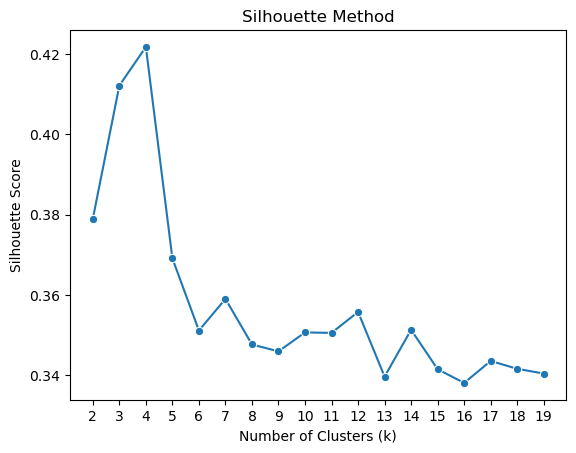

In [2]:
from sklearn.metrics import silhouette_score

silhouette_scores = []

for k in range(2, 20):
    model = KMeans(n_clusters=k, random_state=42)
    labels = model.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)

sns.lineplot(
    x=range(2, 20),
    y=silhouette_scores,
    marker='o'
)

plt.xticks(range(2, 20))
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Method")
plt.show()